# Pileup

The pileup weights (`pileup` in `sidm/configs/corrections.yaml`, applied by default) reweight
the simulated number of true interactions to the 2018 profile, which is built from the
golden-JSON luminosity with a minimum-bias cross section of 69.2 mb. The up and down
variations rebuild that profile with the cross section shifted by its uncertainty, 4.6%
(66.0 and 72.4 mb). The relative change of the signal yield under them is the pileup
uncertainty. This notebook measures it for every signal point:

1. a check that the signal samples were generated with the profile the weights assume;
2. the change of the signal yield under the up and down variations;
3. its statistical precision;
4. the effect on the lepton-jet isolation, the cut of region A most sensitive to pileup;
5. what to assign in the datacards.

Inputs: the merged outputs of the corrections campaign (`corrections_study.CAMPAIGN_DIR`),
which carry every weight variation on the `syst` axis. Simulation only. The yields are those
of the campaign's `2mu2e_sr` and `4mu_sr` channels, the categories with $|\Delta\phi| > 2$,
which are inclusive in the isolation (`systematics_study.CHANNEL`); section 4 adds the
isolation cuts of region A.

In [1]:
import os, sys, warnings
import numpy as np
import hist
import matplotlib.pyplot as plt
import mplhep as hep

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)
BLUE, ORANGE, AQUA, GRAY, BLACK = study.BLUE, study.ORANGE, study.AQUA, study.GRAY, study.BLACK
SIGNALS = study.signal_points()
LIMIT = set(sysstudy.limit_grid(SIGNALS))
print(f"{len(SIGNALS)} signal points, {len(LIMIT)} of them on the limit grid")
print("campaign outputs:", study.CAMPAIGN_DIR)

180 signal points, 96 of them on the limit grid
campaign outputs: /store/user/scampbel/sidm_coffea_outputs/corrections_v1


## Samples

One output at a time, keeping only the cutflow yields and the histograms used below. The
campaign evaluated the photon pixel-veto SF without applying it (corrections README, "The
Condor campaign"); the relative changes studied here do not depend on it, so the weight
categories are used as the campaign stored them.

In [2]:
SHIFTS = ("pileupUp", "pileupDown")
SHOWN = {"2Mu2E": "2Mu2E_500GeV_1p2GeV_1p9mm", "4Mu": "4Mu_500GeV_1p2GeV_1p9mm"}
rows, shown = {}, {}
for s in SIGNALS:
    out = study.load([s])[s]
    fs = study.parse_point(s)["final_state"]
    ch = sysstudy.CHANNEL[fs]
    meta = out["metadata"]
    y = study.campaign_yields(out, ch)
    stored = lambda name, c: out["hists"][name][{"channel": ch, "syst": c}]
    ntrue = {c: stored("pileup_nTrueInt", c) for c in ("uncorrected", "nominal") + SHIFTS}
    iso = {c: stored("lj_isolation_analysis", c) for c in ("nominal",) + SHIFTS}
    rows[s] = {
        "fs": fs,
        "raw": study.raw(out, ch),
        "mean_weight": meta["scaled_sum_weights_corrected"]["pileup"] / meta["scaled_sum_weights"],
        "shift": {c: y[c] / y["nominal"] - 1 for c in SHIFTS},
        "shift_hist": {c: sysstudy.pileup_shift(ntrue["nominal"], ntrue[c]) for c in SHIFTS},
        "half": sysstudy.pileup_halfwidth(ntrue["nominal"], ntrue["pileupUp"], ntrue["pileupDown"]),
        "mean_ntrue": {c: float(np.average(h.axes[0].centers, weights=h.values())) for c, h in ntrue.items()},
        "iso_shift": {c: sysstudy.event_iso_shift(iso["nominal"], iso[c], fs) for c in SHIFTS},
    }
    if s in SHOWN.values():
        shown[s] = ntrue
    del out

# the histograms hold the same events as the cutflows
diff = max(abs(r["shift_hist"][c][0] - r["shift"][c]) for r in rows.values() for c in SHIFTS)
print(f"read {len(rows)} signal points; largest difference between the shifts from the cutflows "
      f"and from the nTrueInt histograms: {diff:.1e}")

read 180 signal points; largest difference between the shifts from the cutflows and from the nTrueInt histograms: 2.0e-15


## 1. The simulated profile

The weights are the ratio of the data profile to the profile the 2018 UL simulation was
generated with, so they describe only samples generated with that profile, and for those
the mean weight over the whole sample is one. The signal samples are private productions,
so this is worth checking: below is the mean pileup weight of each sample over all its
events, before any selection, from the sums of weights the processor records
(`scaled_sum_weights_corrected`).

In [3]:
w = np.array([r["mean_weight"] for r in rows.values()])
print(f"mean pileup weight over each sample, before any selection: {w.min():.4f} to {w.max():.4f} "
      f"({len(w)} signal points)")

mean pileup weight over each sample, before any selection: 0.9992 to 1.0008 (180 signal points)


Every signal sample has a mean weight of one to within 0.1%: they were generated with the
standard 2018 profile, the weights apply to them as they are, and they leave the
normalization unchanged. The distributions of the selected events of two points, in bins of
two interactions (the campaign's integer binning puts 29, 57 and 58 in the bin below, see
the corrections README):

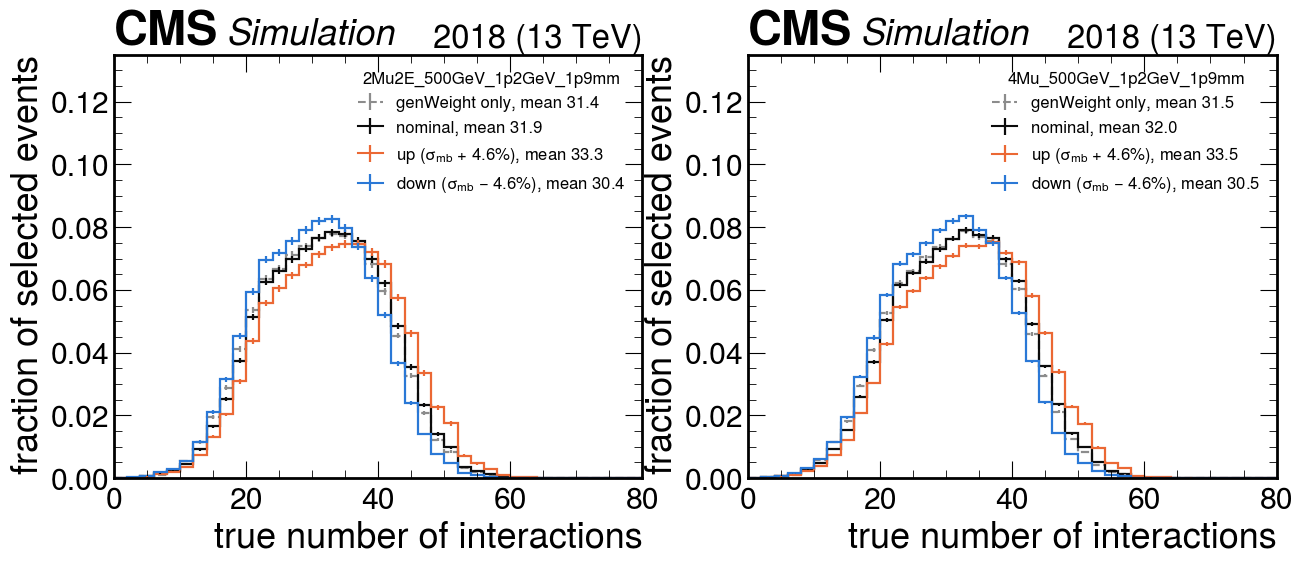

mean number of interactions of the selected events: 31.5 to 33.5; up moves it by +1.49, down by -1.49 (medians over the points)


In [4]:
LABELS = {"uncorrected": "genWeight only", "nominal": "nominal",
          "pileupUp": r"up ($\sigma_{\rm mb}$ + 4.6%)", "pileupDown": r"down ($\sigma_{\rm mb}$ $-$ 4.6%)"}
STYLES = {"uncorrected": (GRAY, "--"), "nominal": (BLACK, "-"), "pileupUp": (ORANGE, "-"), "pileupDown": (BLUE, "-")}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (fs, s) in zip(axes, SHOWN.items()):
    for c, h in shown[s].items():
        color, ls = STYLES[c]
        hep.histplot(study.fractions(h[::hist.rebin(2)]), ax=ax, color=color, ls=ls, lw=1.6,
                     label=f"{LABELS[c]}, mean {rows[s]['mean_ntrue'][c]:.1f}")
    ax.set_xlim(0, 80)
    ax.set_ylim(0, 0.135)
    ax.set_xlabel("true number of interactions")
    ax.set_ylabel("fraction of selected events")
    ax.legend(title=s, fontsize=12, title_fontsize=12, loc="upper right")
study.cms_label(axes)
plt.show()

d_up = [r["mean_ntrue"]["pileupUp"] - r["mean_ntrue"]["nominal"] for r in rows.values()]
d_dn = [r["mean_ntrue"]["pileupDown"] - r["mean_ntrue"]["nominal"] for r in rows.values()]
nom = [r["mean_ntrue"]["nominal"] for r in rows.values()]
print(f"mean number of interactions of the selected events: {min(nom):.1f} to {max(nom):.1f}; "
      f"up moves it by {np.median(d_up):+.2f}, down by {np.median(d_dn):+.2f} (medians over the points)")

## 2. The change of the signal yield

The variations move the mean number of interactions by about $\pm 1.5$, about 5%, as the
cross section does. How much the yield follows depends on how strongly the selection
depends on pileup. Below, for every point, the relative change of the yield under the up
and down variations, with its statistical uncertainty (section 3); filled markers are the
points of the limit grid.

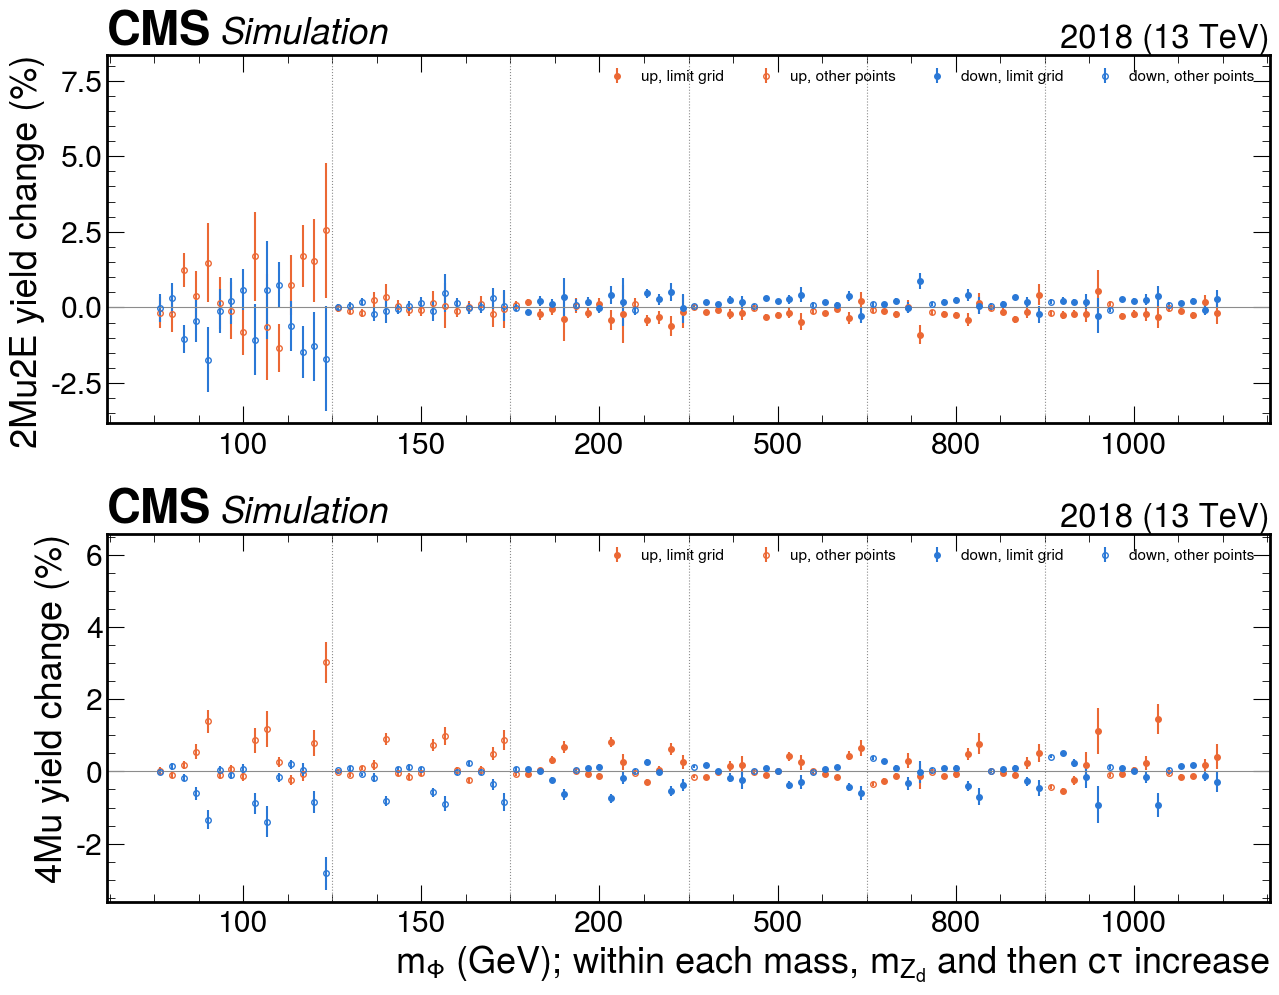

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(15, 11), gridspec_kw={"hspace": 0.3})
for ax, fs in zip(axes, ("2Mu2E", "4Mu")):
    points = sysstudy.ordered_points(SIGNALS, fs)
    x = np.arange(len(points))
    on = np.array([s in LIMIT for s in points])
    for c, color, label in (("pileupUp", ORANGE, "up"), ("pileupDown", BLUE, "down")):
        val = np.array([100 * rows[s]["shift_hist"][c][0] for s in points])
        err = np.array([100 * rows[s]["shift_hist"][c][1] for s in points])
        ax.errorbar(x[on], val[on], err[on], fmt="o", ms=4, color=color, label=f"{label}, limit grid")
        ax.errorbar(x[~on], val[~on], err[~on], fmt="o", ms=4, mfc="none", color=color, label=f"{label}, other points")
    ax.axhline(0, color=GRAY, lw=0.8)
    sysstudy.mass_ticks(ax, points, label=ax is axes[-1])
    ax.set_ylabel(f"{fs} yield change (%)")
    sysstudy.headroom(ax)
    ax.legend(ncol=4, fontsize=11, loc="upper right")
study.cms_label(axes)
plt.show()

## 3. How much of it is statistical

The pileup weight depends only on the number of true interactions, so within one bin of
`pileup_nTrueInt` every event changes by the same factor. The shift of the yield is then a
weighted mean of those per-bin factors, and its statistical uncertainty follows from the sum
of squared weights in each bin (`systematics_study.pileup_shift`). For the half-width of up
and down, the uncertainty is that of the per-event half-difference, since the two shifts
come from the same events and are anti-correlated (`systematics_study.pileup_halfwidth`).

In [6]:
def summary(points):
    half = np.array([100 * abs(rows[s]["half"][0]) for s in points])
    stat = np.array([100 * rows[s]["half"][1] for s in points])
    return half, stat

print(f"{'':6s} {'':11s} {'points':>6s} {'half-width (%)':>24s} {'stat. precision (%)':>20s} {'above 2 sigma':>14s}")
print(f"{'':6s} {'':11s} {'':6s} {'median':>8s} {'max':>7s} {'':8s} {'median':>8s}")
for fs in ("2Mu2E", "4Mu"):
    for label, points in (("all points", [s for s in SIGNALS if rows[s]["fs"] == fs]),
                          ("limit grid", [s for s in LIMIT if rows[s]["fs"] == fs])):
        half, stat = summary(points)
        print(f"{fs:6s} {label:11s} {len(points):6d} {np.median(half):8.2f} {half.max():7.2f} {'':8s} "
              f"{np.median(stat):8.2f} {np.sum(half > 2 * stat):10d}")

print("\npoints with a half-width above 1%:")
for s in SIGNALS:
    h, e = rows[s]["half"]
    if abs(h) > 0.01:
        print(f"  {s:32s} {'limit grid' if s in LIMIT else '':10s} {rows[s]['raw']:6.0f} events: "
              f"{100 * abs(h):.2f} +- {100 * e:.2f}%  (up {100 * rows[s]['shift']['pileupUp']:+.2f}%, "
              f"down {100 * rows[s]['shift']['pileupDown']:+.2f}%)")

                   points           half-width (%)  stat. precision (%)  above 2 sigma
                            median     max            median
2Mu2E  all points      90     0.20    2.12              0.19         16
2Mu2E  limit grid      48     0.22    0.88              0.17         14
4Mu    all points      90     0.16    2.93              0.09         37
4Mu    limit grid      48     0.19    1.19              0.10         21

points with a half-width above 1%:
  2Mu2E_100GeV_0p25GeV_2p0mm                    1610 events: 1.14 +- 0.51%  (up +1.23%, down -1.05%)
  2Mu2E_100GeV_0p25GeV_20p0mm                    270 events: 1.61 +- 1.18%  (up +1.48%, down -1.73%)
  2Mu2E_100GeV_1p2GeV_48p0mm                     273 events: 1.38 +- 1.30%  (up +1.69%, down -1.07%)
  2Mu2E_100GeV_5p0GeV_0p4mm                      485 events: 1.04 +- 0.76%  (up -1.34%, down +0.73%)
  2Mu2E_100GeV_5p0GeV_40p0mm                     504 events: 1.60 +- 0.93%  (up +1.71%, down -1.48%)
  2Mu2E_100GeV_5p0GeV_2

For most points the half-width is a few tenths of a percent and within twice its
statistical precision: the selection hardly depends on pileup, and part of what is seen is
statistical. The values above 1% are at $m_\Phi$ = 100 GeV, which is not on the limit grid,
apart from two 4Mu points at 1000 GeV. Up and down are not mirror images at every point, so
the datacards should keep both (an asymmetric log-normal).

## 4. The isolation

Pileup adds neutral energy to the jet matched to a lepton jet (the CHS jets lose only the
charged pileup), so the isolation is the cut of region A that pileup can move. The
campaign's per-lepton-jet histogram `lj_isolation_analysis` carries the weight variations
too. Below is the change of the region-A isolation efficiency (muon-type lepton jet below 0.3,
the other below 0.5, `systematics_study.ISO_CUTS`), summed over the two lepton jets
(`systematics_study.event_iso_shift`), on top of the yield change above.

In [7]:
for fs in ("2Mu2E", "4Mu"):
    points = [s for s in SIGNALS if rows[s]["fs"] == fs]
    for c in SHIFTS:
        d = np.array([100 * rows[s]["iso_shift"][c] for s in points])
        print(f"{fs:6s} {c:10s}: isolation efficiency changes by {np.median(d):+.3f}% (median), "
              f"{d.min():+.2f} to {d.max():+.2f}%")

total = {s: 0.5 * abs((r["shift"]["pileupUp"] + r["iso_shift"]["pileupUp"])
                      - (r["shift"]["pileupDown"] + r["iso_shift"]["pileupDown"])) for s, r in rows.items()}
for fs in ("2Mu2E", "4Mu"):
    for label, points in (("all points", [s for s in SIGNALS if rows[s]["fs"] == fs]),
                          ("limit grid", [s for s in LIMIT if rows[s]["fs"] == fs])):
        t = np.array([100 * total[s] for s in points])
        print(f"{fs:6s} {label:11s}: half-width with the isolation of region A {np.median(t):.2f}% (median), "
              f"{t.max():.2f}% (max)")

2Mu2E  pileupUp  : isolation efficiency changes by -0.067% (median), -0.89 to +0.23%
2Mu2E  pileupDown: isolation efficiency changes by +0.070% (median), -0.33 to +0.76%
4Mu    pileupUp  : isolation efficiency changes by -0.046% (median), -0.34 to +0.05%
4Mu    pileupDown: isolation efficiency changes by +0.039% (median), -0.03 to +0.30%
2Mu2E  all points : half-width with the isolation of region A 0.25% (median), 2.02% (max)
2Mu2E  limit grid : half-width with the isolation of region A 0.26% (median), 0.97% (max)
4Mu    all points : half-width with the isolation of region A 0.20% (median), 2.69% (max)
4Mu    limit grid : half-width with the isolation of region A 0.18% (median), 1.17% (max)


For a typical point the isolation adds a few hundredths of a percent: the signal lepton jets
are far below the cuts, so the neutral energy of a few more interactions does not move them
across. At a few points with few events it reaches several tenths of a percent, and with it
the half-width on the limit grid is at most about 1% (2Mu2E) and 1.2% (4Mu), as without it.

## 5. What to assign

* One log-normal nuisance, `CMS_pileup`, on the signal only (the background is estimated
  from data), with the same name in every card: correlated between 2mu2e and 4mu, across
  signal points and across the ABCD regions.
* Its value is the up and down change of each point's yield, kept asymmetric
  (`kappa_down/kappa_up`). On the limit grid this is 0.2% for a typical point and 1.2% at
  most; the larger values at $m_\Phi$ = 100 GeV are partly statistical.
* The values must be read at the selection of the limits, from the `pileupUp` and
  `pileupDown` categories of a run with `corrections=True` (they are in every cutflow row,
  `variation_yields()`). The isolation changes them little, so the numbers above are
  already close.
* Not done here, because it needs collision data: the comparison of the reweighted
  simulation with data in the number of reconstructed vertices of a control region, which
  the AN asks for. The profile check of section 1 is the simulation-only part of it.